# NB3 — YOLO26 Semantic Segmentation and Final Comparison

This notebook follows the same overall coding style and output structure as the uploaded NB1 notebook.



## Before running this notebook on Kaggle

Add these Kaggle inputs:

- Raw Moroccan Landing Site Segmentation V2 dataset
- Saved NB0 output
- Saved NB1 output
- Saved NB2 output

NB0 output should contain:

- `all_splits.csv`
- `encoded_masks/`
- `segmentation_common.py`
- `comparison_sample_ids.json`

In [1]:

!pip install -q -U "ultralytics>=8.4.52"

import importlib
import json
import os
import random
import shutil
import sys
import textwrap
import time

from datetime import datetime, timezone
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import yaml

from IPython.display import Markdown, display
from PIL import Image
from tqdm.auto import tqdm
from ultralytics import YOLO


SEED = 42
IMAGE_SIZE = 256
NUM_CLASSES = 2

CLASS_ID_TO_NAME = {
    0: "background",
    1: "landing_site",
}

INPUT_ROOT = Path("/kaggle/input")
WORK_ROOT = Path("/kaggle/working")

OUTPUT_ROOT = WORK_ROOT / "NB3_outputs"
OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)

YOLO_DATA_ROOT = WORK_ROOT / "moroccan_yolo_semantic"


def seed_everything(seed: int = 42) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    torch.backends.cudnn.benchmark = True


seed_everything(SEED)

DEVICE = 0 if torch.cuda.is_available() else "cpu"
USE_AMP = torch.cuda.is_available()

print("Device:", DEVICE)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

print("Mixed precision:", USE_AMP)
print("Output directory:", OUTPUT_ROOT)

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 42.1/42.1 kB 594.7 kB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 6.9 MB/s eta 0:00:00
Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
Device: 0
CUDA available: True
GPU: Tesla T4
Mixed precision: True
Output directory: /kaggle/working/NB3_outputs


## 1. Locate NB0, NB1, NB2 outputs and raw dataset

In [2]:

from pathlib import Path
import json

INPUT_ROOT = Path("/kaggle/input")


print("Attached Kaggle inputs:")

for path in sorted(INPUT_ROOT.iterdir()):
    print(" -", path)



def find_preferred_file(
    filename,
    preferred_folder_name=None,
):

    candidates = sorted(
        INPUT_ROOT.rglob(filename)
    )

    if not candidates:
        return None

    if preferred_folder_name is None:
        return candidates[0]

    return sorted(
        candidates,
        key=lambda path: (
            preferred_folder_name.lower()
            not in str(path).lower(),
            len(str(path)),
        ),
    )[0]



SPLIT_FILE = find_preferred_file(
    "all_splits.csv",
    "NB0_outputs",
)

assert SPLIT_FILE is not None, (
    "NB0 all_splits.csv was not found."
)

NB0_OUTPUT_ROOT = SPLIT_FILE.parents[1]



COMMON_FILE = find_preferred_file(
    "segmentation_common.py",
    "NB0_outputs",
)

assert COMMON_FILE is not None, (
    "NB0 segmentation_common.py was not found."
)

COMMON_DIR = COMMON_FILE.parent



COMPARISON_FILE = find_preferred_file(
    "comparison_sample_ids.json",
    "NB0_outputs",
)

assert COMPARISON_FILE is not None, (
    "NB0 comparison_sample_ids.json was not found."
)


dataset_roots = []

for candidate in INPUT_ROOT.rglob("dataset"):

    if (
        (candidate / "training" / "images").is_dir()
        and (candidate / "training" / "masks").is_dir()
        and (candidate / "testing" / "images").is_dir()
        and (candidate / "testing" / "masks").is_dir()
    ):

        dataset_roots.append(candidate)


assert dataset_roots, (
    "Raw Moroccan landing-site dataset was not found."
)


DATA_ROOT = sorted(
    dataset_roots,
    key=lambda path: len(str(path)),
)[0]



NB1_METRICS_FILE = find_preferred_file(
    "deeplabv3_metrics.json",
    "NB1_outputs",
)

assert NB1_METRICS_FILE is not None, (
    "NB1 deeplabv3_metrics.json was not found."
)

NB1_OUTPUT_ROOT = NB1_METRICS_FILE.parent


NB2_METRICS_FILE = find_preferred_file(
    "segformer_metrics.json",
    "NB2_outputs",
)



if NB2_METRICS_FILE is None:

    similar_nb2_files = sorted(
        INPUT_ROOT.rglob(
            "*segformer*metric*.json"
        )
    )

    if similar_nb2_files:
        NB2_METRICS_FILE = similar_nb2_files[0]


assert NB2_METRICS_FILE is not None, (
    "NB2 segformer_metrics.json was not found. "
    "Attach the completed NB2 Kaggle notebook output "
    "before running NB3 Task H."
)

NB2_OUTPUT_ROOT = NB2_METRICS_FILE.parent


with NB1_METRICS_FILE.open(
    "r",
    encoding="utf-8",
) as file:

    nb1_payload = json.load(file)


nb2_payload = None

if NB2_METRICS_FILE is not None:

    with NB2_METRICS_FILE.open(
        "r",
        encoding="utf-8",
    ) as file:

        nb2_payload = json.load(file)


print("\nNB0 split file:", SPLIT_FILE)

print(
    "NB0 output root:",
    NB0_OUTPUT_ROOT,
)

print(
    "NB0 common module:",
    COMMON_FILE,
)

print(
    "Comparison sample IDs:",
    COMPARISON_FILE,
)

print(
    "Raw dataset root:",
    DATA_ROOT,
)

print(
    "NB1 metrics:",
    NB1_METRICS_FILE,
)

print(
    "NB2 metrics:",
    NB2_METRICS_FILE,
)


print("\nInput status:")

print(
    "NB0 ready:",
    True,
)

print(
    "NB1 ready:",
    NB1_METRICS_FILE is not None,
)

print(
    "NB2 ready:",
    NB2_METRICS_FILE is not None,
)


if (
    NB1_METRICS_FILE is not None
    and NB2_METRICS_FILE is not None
):

    print(
        "\nNB1 and NB2 metrics are ready "
        "for Task H comparison."
    )

else:

    print(
        "\nTask H is not ready yet."
    )

Attached Kaggle inputs:
 - /kaggle/input/datasets
 - /kaggle/input/notebooks

NB0 split file: /kaggle/input/notebooks/happysruti/438-ass-1/NB0_outputs/splits/all_splits.csv
NB0 output root: /kaggle/input/notebooks/happysruti/438-ass-1/NB0_outputs
NB0 common module: /kaggle/input/notebooks/happysruti/438-ass-1/NB0_outputs/common/segmentation_common.py
Comparison sample IDs: /kaggle/input/notebooks/happysruti/438-ass-1/NB0_outputs/comparison_sample_ids.json
Raw dataset root: /kaggle/input/datasets/sumaiyaakter4789/moroccan-landing-site-segmentation/Moroccan Aircraft Emergency Landing Sites Semantic Segmentation Dataset/dataset
NB1 metrics: /kaggle/input/notebooks/fahmidajannat/nb1-deeplabv3-semantic-segmentation/NB1_outputs/deeplabv3_metrics.json
NB2 metrics: /kaggle/input/notebooks/happysruti/438-nb2/NB2_outputs/segformer_b0_metrics.json

Input status:
NB0 ready: True
NB1 ready: True
NB2 ready: True

NB1 and NB2 metrics are ready for Task H comparison.


## 2. Load the split manifest

In [3]:


split_df = pd.read_csv(SPLIT_FILE)

required_columns = {
    "image_id",
    "split",
    "image_relpath",
    "encoded_mask_relpath",
    "group_id",
}

missing_columns = required_columns - set(split_df.columns)

assert not missing_columns, (
    f"NB0 manifest is missing columns: {missing_columns}"
)

assert split_df["image_id"].is_unique

assert set(split_df["split"]) == {
    "train",
    "val",
    "test",
}


expected_counts = {
    "train": 1416,
    "val": 314,
    "test": 360,
}

actual_counts = (
    split_df["split"]
    .value_counts()
    .to_dict()
)

assert actual_counts == expected_counts, (
    f"Expected {expected_counts}, found {actual_counts}"
)


group_split_counts = (
    split_df
    .groupby("group_id")["split"]
    .nunique()
)

assert group_split_counts.max() == 1, (
    "A related group crosses split boundaries."
)


split_df["resolved_image_path"] = (
    split_df["image_relpath"].apply(
        lambda relative_path: str(
            DATA_ROOT / relative_path
        )
    )
)

split_df["resolved_mask_path"] = (
    split_df["encoded_mask_relpath"].apply(
        lambda relative_path: str(
            NB0_OUTPUT_ROOT / relative_path
        )
    )
)


missing_images = [
    path
    for path in split_df["resolved_image_path"]
    if not Path(path).exists()
]

missing_masks = [
    path
    for path in split_df["resolved_mask_path"]
    if not Path(path).exists()
]

assert not missing_images, (
    f"Some images were not found: {missing_images[:3]}"
)

assert not missing_masks, (
    f"Some masks were not found: {missing_masks[:3]}"
)


train_df = (
    split_df[split_df["split"] == "train"]
    .reset_index(drop=True)
)

val_df = (
    split_df[split_df["split"] == "val"]
    .reset_index(drop=True)
)

test_df = (
    split_df[split_df["split"] == "test"]
    .reset_index(drop=True)
)


display(
    pd.DataFrame(
        {
            "split": ["train", "validation", "test"],
            "samples": [
                len(train_df),
                len(val_df),
                len(test_df),
            ],
        }
    )
)

print("Shared NB0 split loaded successfully.")

,split,samples
0,train,1416
1,validation,314
2,test,360


Shared NB0 split loaded successfully.


## 3. Import NB0 preprocessing and prepare YOLO semantic data

In [4]:


if str(COMMON_DIR) not in sys.path:
    sys.path.insert(0, str(COMMON_DIR))

importlib.invalidate_caches()

import segmentation_common
importlib.reload(segmentation_common)

from segmentation_common import load_mask


if YOLO_DATA_ROOT.exists():
    shutil.rmtree(YOLO_DATA_ROOT)

for split_name in ["train", "val", "test"]:
    (YOLO_DATA_ROOT / "images" / split_name).mkdir(parents=True, exist_ok=True)
    (YOLO_DATA_ROOT / "masks" / split_name).mkdir(parents=True, exist_ok=True)

yolo_manifest_rows = []

for _, row in tqdm(
    split_df.iterrows(),
    total=len(split_df),
    desc="Prepare YOLO semantic dataset",
):
    image_id = str(row["image_id"])
    split_name = str(row["split"])

    source_image = Path(row["resolved_image_path"])
    source_mask = Path(row["resolved_mask_path"])

    destination_image = (
        YOLO_DATA_ROOT / "images" / split_name
        / f"{image_id}{source_image.suffix.lower()}"
    )
    destination_mask = (
        YOLO_DATA_ROOT / "masks" / split_name
        / f"{image_id}.png"
    )

    shutil.copy2(source_image, destination_image)

    mask = load_mask(source_mask).astype(np.uint8)
    assert mask.ndim == 2, f"Mask is not single-channel: {source_mask}"

    mask_values = set(np.unique(mask).tolist())
    assert mask_values.issubset({0, 1, 255}), (
        f"Invalid mask values in {source_mask}: {mask_values}"
    )

    Image.fromarray(mask).save(destination_mask)

    yolo_manifest_rows.append({
        "image_id": image_id,
        "split": split_name,
        "image_path": str(destination_image),
        "mask_path": str(destination_mask),
    })

yolo_manifest_df = pd.DataFrame(yolo_manifest_rows)
prepared_counts = yolo_manifest_df["split"].value_counts().to_dict()
assert prepared_counts == expected_counts

display(yolo_manifest_df.head())
print("YOLO semantic dataset prepared successfully.")

Prepare YOLO semantic dataset:   0%|          | 0/2090 [00:00<?, ?it/s]

,image_id,split,image_path,mask_path
0,training_00001,train,/kaggle/working/moroccan_yolo_semantic/images/...,/kaggle/working/moroccan_yolo_semantic/masks/t...
1,training_00002,train,/kaggle/working/moroccan_yolo_semantic/images/...,/kaggle/working/moroccan_yolo_semantic/masks/t...
2,training_00004,train,/kaggle/working/moroccan_yolo_semantic/images/...,/kaggle/working/moroccan_yolo_semantic/masks/t...
3,training_00005,train,/kaggle/working/moroccan_yolo_semantic/images/...,/kaggle/working/moroccan_yolo_semantic/masks/t...
4,training_00006,train,/kaggle/working/moroccan_yolo_semantic/images/...,/kaggle/working/moroccan_yolo_semantic/masks/t...


YOLO semantic dataset prepared successfully.


In [5]:

DATA_YAML = (
    OUTPUT_ROOT
    / "moroccan_landing_site_semantic.yaml"
)

dataset_yaml = {
    "path": str(YOLO_DATA_ROOT),
    "train": "images/train",
    "val": "images/val",
    "test": "images/test",
    "masks_dir": "masks",
    "names": CLASS_ID_TO_NAME,
}

with DATA_YAML.open(
    "w",
    encoding="utf-8",
) as file:
    yaml.safe_dump(
        dataset_yaml,
        file,
        sort_keys=False,
    )

print(
    DATA_YAML.read_text(
        encoding="utf-8"
    )
)

path: /kaggle/working/moroccan_yolo_semantic
train: images/train
val: images/val
test: images/test
masks_dir: masks
names:
  0: background
  1: landing_site



## 4. YOLO26-Sem model, configuration, and metric functions

In [6]:


MODEL_NAME = "yolo26n-sem.pt"
IMG_SIZE = IMAGE_SIZE
EPOCHS = 50
BATCH = 16 if torch.cuda.is_available() else 2
WORKERS = 2


CONFIG = {
    "notebook": "NB3",
    "model": "YOLO26n-Sem",
    "checkpoint": MODEL_NAME,

    "seed": SEED,
    "image_size": IMG_SIZE,
    "num_classes": NUM_CLASSES,

    "batch_size": BATCH,
    "epochs": EPOCHS,
    "workers": WORKERS,

    "optimizer": "AdamW",
    "learning_rate": 1e-3,
    "final_lr_fraction": 0.01,
    "weight_decay": 1e-4,
    "warmup_epochs": 3.0,
    "learning_rate_schedule": "cosine",

    "mixed_precision": torch.cuda.is_available(),

    "pretrained": True,

    "early_stopping": False,

    "loss": (
        "Ultralytics YOLO26 semantic "
        "segmentation loss"
    ),

    "class_weights": None,

    "split_file": str(SPLIT_FILE),
    "nb0_output_root": str(NB0_OUTPUT_ROOT),
    "raw_dataset_root": str(DATA_ROOT),

    "saved_at": datetime.now(
        timezone.utc
    ).isoformat(),
}


display(
    pd.DataFrame(
        {
            "parameter": CONFIG.keys(),
            "value": [
                str(value)
                for value in CONFIG.values()
            ],
        }
    )
)


print("Model:", MODEL_NAME)
print("Epochs:", EPOCHS)
print("Image size:", IMG_SIZE)
print("Batch size:", BATCH)
print("Workers:", WORKERS)
print("Optimizer:", CONFIG["optimizer"])
print("Learning rate:", CONFIG["learning_rate"])
print("Weight decay:", CONFIG["weight_decay"])
print("Mixed precision:", CONFIG["mixed_precision"])
print("Early stopping:", CONFIG["early_stopping"])
print("Device:", DEVICE)


,parameter,value
0,notebook,NB3
1,model,YOLO26n-Sem
2,checkpoint,yolo26n-sem.pt
3,seed,42
4,image_size,256
5,num_classes,2
6,batch_size,16
7,epochs,50
8,workers,2
9,optimizer,AdamW


Model: yolo26n-sem.pt
Epochs: 50
Image size: 256
Batch size: 16
Workers: 2
Optimizer: AdamW
Learning rate: 0.001
Weight decay: 0.0001
Mixed precision: True
Early stopping: False
Device: 0


In [7]:


IGNORE_INDEX = 255


def update_confusion_matrix(
    confusion_matrix: np.ndarray,
    ground_truth: np.ndarray,
    prediction: np.ndarray,
) -> np.ndarray:

    valid = ground_truth != IGNORE_INDEX
    valid &= ground_truth >= 0
    valid &= ground_truth < NUM_CLASSES
    valid &= prediction >= 0
    valid &= prediction < NUM_CLASSES

    encoded = (
        NUM_CLASSES
        * ground_truth[valid].astype(np.int64)
        + prediction[valid].astype(np.int64)
    )

    counts = np.bincount(
        encoded,
        minlength=NUM_CLASSES ** 2,
    )

    confusion_matrix += counts.reshape(
        NUM_CLASSES,
        NUM_CLASSES,
    )

    return confusion_matrix


def metrics_from_confusion_matrix(
    confusion: np.ndarray,
) -> dict:

    confusion = confusion.astype(np.float64)

    true_positive = np.diag(confusion)
    actual_pixels = confusion.sum(axis=1)
    predicted_pixels = confusion.sum(axis=0)

    union = (
        actual_pixels
        + predicted_pixels
        - true_positive
    )

    per_class_iou = np.divide(
        true_positive,
        union,
        out=np.zeros_like(true_positive),
        where=union > 0,
    )

    per_class_accuracy = np.divide(
        true_positive,
        actual_pixels,
        out=np.zeros_like(true_positive),
        where=actual_pixels > 0,
    )

    per_class_dice = np.divide(
        2 * true_positive,
        actual_pixels + predicted_pixels,
        out=np.zeros_like(true_positive),
        where=(actual_pixels + predicted_pixels) > 0,
    )

    overall_pixel_accuracy = (
        true_positive.sum() / confusion.sum()
        if confusion.sum() > 0
        else 0.0
    )

    return {
        "mean_iou": float(np.mean(per_class_iou)),
        "overall_pixel_accuracy": float(
            overall_pixel_accuracy
        ),
        "mean_pixel_accuracy": float(
            np.mean(per_class_accuracy)
        ),
        "mean_dice": float(
            np.mean(per_class_dice)
        ),
        "per_class_iou": {
            CLASS_ID_TO_NAME[index]: float(value)
            for index, value in enumerate(per_class_iou)
        },
        "per_class_accuracy": {
            CLASS_ID_TO_NAME[index]: float(value)
            for index, value in enumerate(
                per_class_accuracy
            )
        },
        "per_class_dice": {
            CLASS_ID_TO_NAME[index]: float(value)
            for index, value in enumerate(
                per_class_dice
            )
        },
    }


def image_metrics(
    ground_truth: np.ndarray,
    prediction: np.ndarray,
) -> dict:

    confusion = np.zeros(
        (NUM_CLASSES, NUM_CLASSES),
        dtype=np.int64,
    )

    confusion = update_confusion_matrix(
        confusion,
        ground_truth,
        prediction,
    )

    return metrics_from_confusion_matrix(
        confusion
    )


def extract_semantic_prediction(
    result,
    output_shape: tuple,
) -> np.ndarray:

    semantic_mask = result.semantic_mask.data

    if torch.is_tensor(semantic_mask):
        semantic_mask = (
            semantic_mask
            .detach()
            .cpu()
            .numpy()
        )

    prediction = np.asarray(
        semantic_mask
    )

    prediction = np.squeeze(
        prediction
    )

    if prediction.ndim == 3:
        if prediction.shape[0] == NUM_CLASSES:
            prediction = np.argmax(
                prediction,
                axis=0,
            )
        elif prediction.shape[-1] == NUM_CLASSES:
            prediction = np.argmax(
                prediction,
                axis=-1,
            )
        else:
            prediction = prediction[0]

    if prediction.ndim != 2:
        raise ValueError(
            "Unexpected semantic prediction "
            f"shape: {prediction.shape}"
        )

    prediction = prediction.astype(
        np.uint8
    )

    if prediction.shape != output_shape:
        prediction = cv2.resize(
            prediction,
            (
                output_shape[1],
                output_shape[0],
            ),
            interpolation=cv2.INTER_NEAREST,
        )

    return prediction

## 5. Train YOLO26-Sem

In [8]:

model = YOLO(MODEL_NAME)

print("Loaded model:", MODEL_NAME)
print("Detected task:", model.task)

assert model.task == "semantic", (
    "The loaded model is not a semantic segmentation checkpoint."
)

Loaded model: yolo26n-sem.pt
Detected task: semantic


In [9]:

model = YOLO(
    CONFIG["checkpoint"]
)


print("Starting YOLO26-Sem training...")
print("Checkpoint:", CONFIG["checkpoint"])
print("Epochs:", CONFIG["epochs"])
print("Batch size:", CONFIG["batch_size"])
print("Mixed precision:", CONFIG["mixed_precision"])


training_start_time = time.time()


train_results = model.train(
    data=str(DATA_YAML),

    epochs=CONFIG["epochs"],

    imgsz=CONFIG["image_size"],
    batch=CONFIG["batch_size"],

    optimizer=CONFIG["optimizer"],
    lr0=CONFIG["learning_rate"],
    lrf=CONFIG["final_lr_fraction"],
    weight_decay=CONFIG["weight_decay"],
    warmup_epochs=CONFIG["warmup_epochs"],
    cos_lr=True,

    amp=CONFIG["mixed_precision"],
    pretrained=CONFIG["pretrained"],

    device=DEVICE,
    workers=CONFIG["workers"],

    cache="ram",

    project=str(OUTPUT_ROOT),
    name="yolo26n_sem_train",
    exist_ok=True,

    save=True,
    plots=True,
    val=True,
    verbose=True,

    seed=CONFIG["seed"],
)


training_time_seconds = (
    time.time()
    - training_start_time
)

training_time_minutes = (
    training_time_seconds
    / 60
)


TRAIN_RUN_DIR = (
    OUTPUT_ROOT
    / "yolo26n_sem_train"
)

BEST_MODEL_PATH = (
    TRAIN_RUN_DIR
    / "weights"
    / "best.pt"
)

LAST_MODEL_PATH = (
    TRAIN_RUN_DIR
    / "weights"
    / "last.pt"
)


assert BEST_MODEL_PATH.exists(), (
    "YOLO best.pt checkpoint was not saved."
)

assert LAST_MODEL_PATH.exists(), (
    "YOLO last.pt checkpoint was not saved."
)


best_model = YOLO(
    str(BEST_MODEL_PATH)
)


print("Training complete.")
print(
    f"Training time: "
    f"{training_time_minutes:.2f} minutes"
)
print("Best checkpoint:", BEST_MODEL_PATH)
print("Last checkpoint:", LAST_MODEL_PATH)


Starting YOLO26-Sem training...
Checkpoint: yolo26n-sem.pt
Epochs: 50
Batch size: 16
Mixed precision: True
Ultralytics 8.4.95 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=ram, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/kaggle/working/NB3_outputs/moroccan_landing_site_semantic.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dis=6.0, distill_model=None, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=256, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n-

In [10]:

RESULTS_CSV = (
    TRAIN_RUN_DIR
    / "results.csv"
)

assert RESULTS_CSV.exists(), (
    "YOLO results.csv was not found."
)

history_df = pd.read_csv(
    RESULTS_CSV
)

history_df.columns = [
    column.strip()
    for column in history_df.columns
]

actual_trained_epochs = len(
    history_df
)

assert actual_trained_epochs == CONFIG["epochs"], (
    f"Expected {CONFIG['epochs']} completed epochs, "
    f"but found {actual_trained_epochs}."
)


miou_columns = [
    column
    for column in history_df.columns
    if "miou" in column.lower()
]

if miou_columns:
    val_miou_column = miou_columns[0]

    best_history_index = (
        history_df[
            val_miou_column
        ].idxmax()
    )

    best_epoch = int(
        history_df.loc[
            best_history_index,
            "epoch",
        ]
    ) + 1

    best_val_miou = float(
        history_df.loc[
            best_history_index,
            val_miou_column,
        ]
    )

else:
    val_miou_column = None
    best_epoch = actual_trained_epochs
    best_val_miou = None


history_df.to_csv(
    OUTPUT_ROOT
    / "yolo_sem_training_history.csv",
    index=False,
)


print("Actual trained epochs:", actual_trained_epochs)

if best_val_miou is not None:
    print(
        f"Best validation mIoU: "
        f"{best_val_miou:.4f} "
        f"at epoch {best_epoch}."
    )

display(history_df.tail())


Actual trained epochs: 50
Best validation mIoU: 0.8481 at epoch 45.


,epoch,time,train/ce_loss,train/dice_loss,train/aux_loss,metrics/mIoU,metrics/pixel_acc,val/ce_loss,val/dice_loss,val/aux_loss,lr/pg0,lr/pg1,lr/pg2
45,46,803.494,0.15911,0.10132,0.06657,0.84449,0.93267,0.17709,0.10929,0,0.000034,0.000034,0.000034
46,47,818.209,0.16594,0.10331,0.06885,0.84419,0.93173,0.17412,0.10940,0,0.000026,0.000026,0.000026
47,48,832.803,0.16096,0.10088,0.06689,0.84393,0.93184,0.17475,0.10960,0,0.000019,0.000019,0.000019
48,49,847.602,0.15192,0.09983,0.06415,0.84569,0.93285,0.17519,0.10804,0,0.000014,0.000014,0.000014
49,50,862.277,0.16079,0.10163,0.06685,0.84513,0.93258,0.17551,0.10892,0,0.000011,0.000011,0.000011


## 6. Training curves

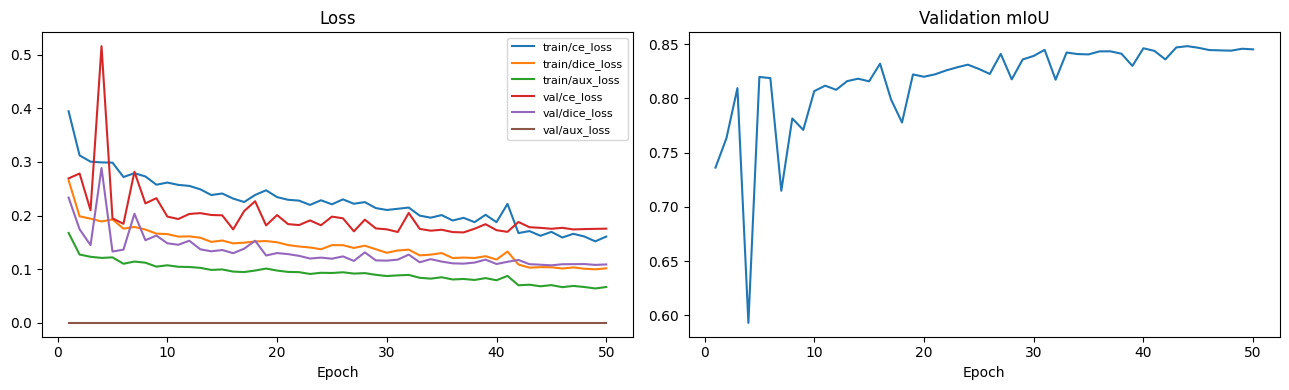

In [11]:

train_loss_columns = [
    column
    for column in history_df.columns
    if (
        "train" in column.lower()
        and "loss" in column.lower()
    )
]

validation_loss_columns = [
    column
    for column in history_df.columns
    if (
        "val" in column.lower()
        and "loss" in column.lower()
    )
]


fig, axes = plt.subplots(
    1,
    2,
    figsize=(13, 4),
)


for column in train_loss_columns:
    axes[0].plot(
        history_df["epoch"],
        history_df[column],
        label=column,
    )


for column in validation_loss_columns:
    axes[0].plot(
        history_df["epoch"],
        history_df[column],
        label=column,
    )


axes[0].set_title("Loss")
axes[0].set_xlabel("Epoch")
axes[0].legend(fontsize=8)


if val_miou_column is not None:
    axes[1].plot(
        history_df["epoch"],
        history_df[val_miou_column],
    )

    axes[1].set_title(
        "Validation mIoU"
    )

else:
    axes[1].text(
        0.5,
        0.5,
        "Validation mIoU was not saved\n"
        "as a separate results.csv column.",
        ha="center",
        va="center",
        transform=axes[1].transAxes,
    )

    axes[1].set_title(
        "Validation mIoU"
    )


axes[1].set_xlabel("Epoch")

plt.tight_layout()

plt.savefig(
    OUTPUT_ROOT
    / "yolo_sem_training_curves.png",
    dpi=160,
)

plt.show()

## 7. Test-set evaluation

In [12]:


test_yolo_df = (
    yolo_manifest_df[
        yolo_manifest_df["split"] == "test"
    ]
    .sort_values("image_id")
    .reset_index(drop=True)
)


PREDICTION_DIR = (
    OUTPUT_ROOT
    / "test_predictions"
)

PREDICTION_DIR.mkdir(
    parents=True,
    exist_ok=True,
)


test_confusion = np.zeros(
    (NUM_CLASSES, NUM_CLASSES),
    dtype=np.int64,
)


per_image_records = []


test_start_time = time.time()


for _, row in tqdm(
    test_yolo_df.iterrows(),
    total=len(test_yolo_df),
    desc="Evaluate test",
):

    ground_truth = np.asarray(
        Image.open(
            row["mask_path"]
        ),
        dtype=np.uint8,
    )


    results = best_model.predict(
        source=row["image_path"],
        imgsz=CONFIG["image_size"],
        device=DEVICE,
        verbose=False,
    )


    prediction = extract_semantic_prediction(
        results[0],
        ground_truth.shape,
    )


    test_confusion = update_confusion_matrix(
        test_confusion,
        ground_truth,
        prediction,
    )


    current_metrics = image_metrics(
        ground_truth,
        prediction,
    )


    prediction_path = (
        PREDICTION_DIR
        / f"{row['image_id']}_yolo_sem_pred.png"
    )


    Image.fromarray(
        prediction
    ).save(
        prediction_path
    )


    per_image_records.append(
        {
            "image_id": row["image_id"],
            "split": "test",
            "mean_iou": (
                current_metrics["mean_iou"]
            ),
            "landing_site_iou": (
                current_metrics[
                    "per_class_iou"
                ]["landing_site"]
            ),
            "background_iou": (
                current_metrics[
                    "per_class_iou"
                ]["background"]
            ),
            "mean_dice": (
                current_metrics["mean_dice"]
            ),
            "prediction_path": str(
                prediction_path
            ),
        }
    )


test_inference_time_seconds = (
    time.time()
    - test_start_time
)


test_metrics = (
    metrics_from_confusion_matrix(
        test_confusion
    )
)


test_per_image_df = pd.DataFrame(
    per_image_records
)


per_class_metrics_df = pd.DataFrame(
    [
        {
            "class_id": class_id,
            "class_name": (
                CLASS_ID_TO_NAME[class_id]
            ),
            "iou": (
                test_metrics[
                    "per_class_iou"
                ][CLASS_ID_TO_NAME[class_id]]
            ),
            "pixel_accuracy": (
                test_metrics[
                    "per_class_accuracy"
                ][CLASS_ID_TO_NAME[class_id]]
            ),
            "dice_f1": (
                test_metrics[
                    "per_class_dice"
                ][CLASS_ID_TO_NAME[class_id]]
            ),
        }
        for class_id in range(NUM_CLASSES)
    ]
)


confusion_df = pd.DataFrame(
    test_confusion,
    index=[
        f"true_{CLASS_ID_TO_NAME[index]}"
        for index in range(NUM_CLASSES)
    ],
    columns=[
        f"pred_{CLASS_ID_TO_NAME[index]}"
        for index in range(NUM_CLASSES)
    ],
)


display(
    Markdown("### Overall test metrics")
)

display(
    pd.DataFrame(
        [
            {
                "mIoU": test_metrics["mean_iou"],
                "overall_pixel_accuracy": (
                    test_metrics[
                        "overall_pixel_accuracy"
                    ]
                ),
                "mean_pixel_accuracy": (
                    test_metrics[
                        "mean_pixel_accuracy"
                    ]
                ),
                "mean_dice_f1": (
                    test_metrics["mean_dice"]
                ),
            }
        ]
    )
)

display(
    Markdown("### Per-class metrics")
)

display(per_class_metrics_df)

display(
    Markdown(
        "### Pixel-level confusion matrix"
    )
)

display(confusion_df)

Evaluate test:   0%|          | 0/360 [00:00<?, ?it/s]

### Overall test metrics

,mIoU,overall_pixel_accuracy,mean_pixel_accuracy,mean_dice_f1
0,0.804132,0.907141,0.881597,0.889701


### Per-class metrics

,class_id,class_name,iou,pixel_accuracy,dice_f1
0,0,background,0.875398,0.949995,0.933559
1,1,landing_site,0.732866,0.813199,0.845843


### Pixel-level confusion matrix

,pred_background,pred_landing_site
true_background,15391728,810173
true_landing_site,1380656,6010403


Saved NB3 metrics and CSV outputs to: /kaggle/working/NB3_outputs


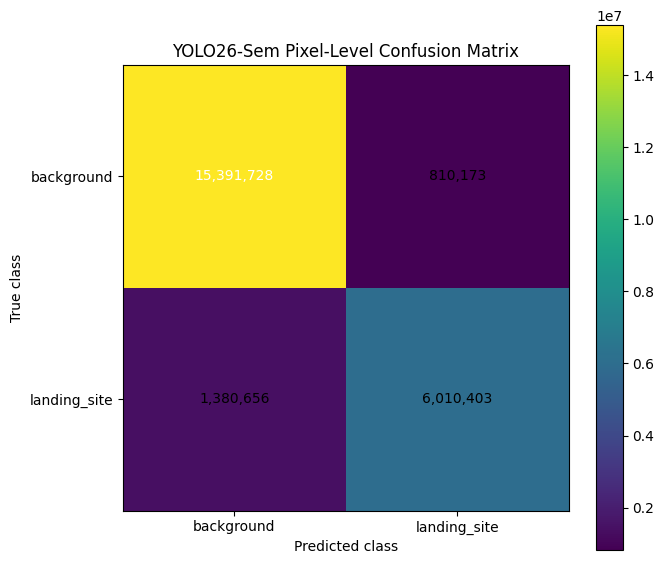

In [13]:

metrics_payload = {
    "notebook": "NB3",
    "model": "YOLO26n-Sem",
    "dataset": (
        "Moroccan Landing Site "
        "Segmentation V2"
    ),
    "split_source": str(SPLIT_FILE),
    "nb0_output_root": str(
        NB0_OUTPUT_ROOT
    ),
    "best_epoch": int(best_epoch),
    "trained_epochs": int(
        actual_trained_epochs
    ),
    "training_time_seconds": float(
        training_time_seconds
    ),
    "test_inference_time_seconds": float(
        test_inference_time_seconds
    ),
    "metrics": test_metrics,
    "confusion_matrix": (
        test_confusion
        .astype(int)
        .tolist()
    ),
    "class_names": CLASS_ID_TO_NAME,
    "config": CONFIG,
    "saved_at": datetime.now(
        timezone.utc
    ).isoformat(),
}


YOLO_METRICS_FILE = (
    OUTPUT_ROOT
    / "yolo_sem_metrics.json"
)


with YOLO_METRICS_FILE.open(
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        metrics_payload,
        file,
        indent=2,
    )


per_class_metrics_df.to_csv(
    OUTPUT_ROOT
    / "yolo_sem_per_class_metrics.csv",
    index=False,
)


test_per_image_df.to_csv(
    OUTPUT_ROOT
    / "yolo_sem_per_image_test_metrics.csv",
    index=False,
)


confusion_df.to_csv(
    OUTPUT_ROOT
    / "yolo_sem_confusion_matrix.csv",
)


with (
    OUTPUT_ROOT
    / "yolo_sem_config.json"
).open(
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        CONFIG,
        file,
        indent=2,
    )


print(
    "Saved NB3 metrics and CSV outputs to:",
    OUTPUT_ROOT,
)# Plot and save the pixel-level confusion matrix.
fig, axis = plt.subplots(
    figsize=(7, 6)
)

matrix_image = axis.imshow(
    test_confusion,
    interpolation="nearest",
)

plt.colorbar(
    matrix_image,
    ax=axis,
)

axis.set_xticks(
    np.arange(NUM_CLASSES)
)

axis.set_yticks(
    np.arange(NUM_CLASSES)
)

axis.set_xticklabels(
    [
        CLASS_ID_TO_NAME[index]
        for index in range(NUM_CLASSES)
    ]
)

axis.set_yticklabels(
    [
        CLASS_ID_TO_NAME[index]
        for index in range(NUM_CLASSES)
    ]
)

axis.set_xlabel(
    "Predicted class"
)

axis.set_ylabel(
    "True class"
)

axis.set_title(
    "YOLO26-Sem Pixel-Level Confusion Matrix"
)

threshold = (
    test_confusion.max() / 2
)

for row_index in range(NUM_CLASSES):
    for column_index in range(NUM_CLASSES):
        value = test_confusion[
            row_index,
            column_index,
        ]

        axis.text(
            column_index,
            row_index,
            f"{value:,}",
            ha="center",
            va="center",
            color=(
                "white"
                if value > threshold
                else "black"
            ),
        )

plt.tight_layout()

plt.savefig(
    OUTPUT_ROOT
    / "yolo_sem_confusion_matrix.png",
    dpi=160,
)

plt.show()

## 8. Error analysis

,image_id,split,mean_iou,landing_site_iou,background_iou,mean_dice,prediction_path
0,testing_00273,test,0.073102,0.001801,0.144403,0.127979,/kaggle/working/NB3_outputs/test_predictions/t...
1,testing_00341,test,0.193062,0.000000,0.386124,0.278564,/kaggle/working/NB3_outputs/test_predictions/t...
2,testing_00088,test,0.207199,0.000000,0.414398,0.292986,/kaggle/working/NB3_outputs/test_predictions/t...
3,testing_00005,test,0.248029,0.312996,0.183061,0.393118,/kaggle/working/NB3_outputs/test_predictions/t...
4,testing_00172,test,0.264381,0.000000,0.528763,0.345876,/kaggle/working/NB3_outputs/test_predictions/t...


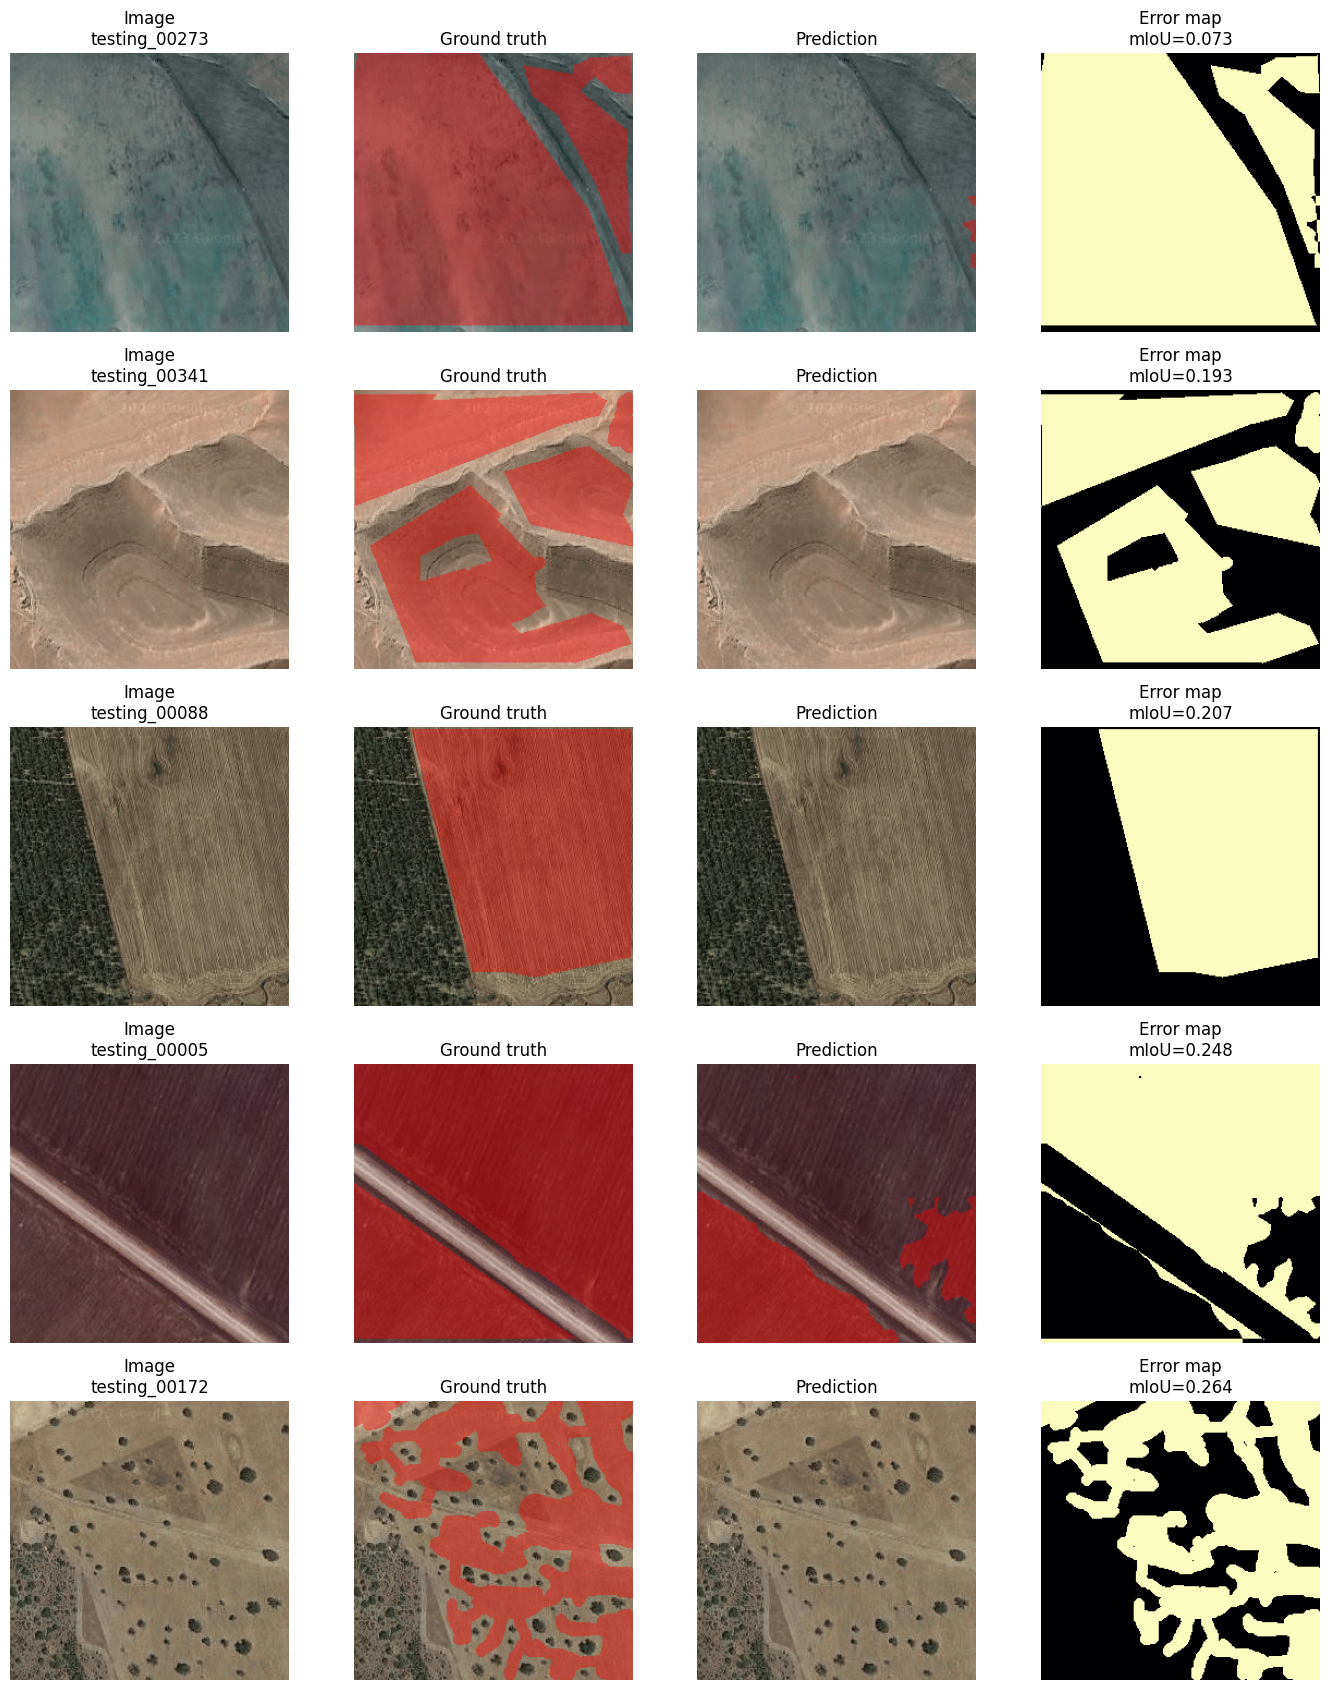

In [14]:


def overlay_mask(
    rgb_image: np.ndarray,
    mask: np.ndarray,
    alpha: float = 0.40,
) -> np.ndarray:

    overlay = rgb_image.copy()

    red = np.zeros_like(
        overlay
    )

    red[..., 0] = 1.0

    mask_bool = mask == 1

    overlay[mask_bool] = (
        (1 - alpha)
        * overlay[mask_bool]
        + alpha
        * red[mask_bool]
    )

    return np.clip(
        overlay,
        0.0,
        1.0,
    )


worst_df = (
    test_per_image_df
    .sort_values(
        [
            "mean_iou",
            "landing_site_iou",
        ],
        ascending=True,
    )
    .head(5)
    .reset_index(drop=True)
)


display(worst_df)


fig, axes = plt.subplots(
    len(worst_df),
    4,
    figsize=(
        14,
        3.4 * len(worst_df),
    ),
)


if len(worst_df) == 1:
    axes = np.expand_dims(
        axes,
        axis=0,
    )


for row_index, result_row in (
    worst_df.iterrows()
):

    manifest_row = (
        test_yolo_df[
            test_yolo_df[
                "image_id"
            ].astype(str)
            == str(
                result_row["image_id"]
            )
        ]
        .iloc[0]
    )


    image = np.asarray(
        Image.open(
            manifest_row["image_path"]
        ).convert("RGB"),
        dtype=np.uint8,
    )


    ground_truth = np.asarray(
        Image.open(
            manifest_row["mask_path"]
        ),
        dtype=np.uint8,
    )


    prediction = np.asarray(
        Image.open(
            result_row[
                "prediction_path"
            ]
        ),
        dtype=np.uint8,
    )


    error_map = (
        ground_truth != prediction
    ).astype(np.uint8)


    image_float = (
        image.astype(np.float32)
        / 255.0
    )


    axes[row_index, 0].imshow(
        image_float
    )

    axes[row_index, 0].set_title(
        f"Image\n{result_row['image_id']}"
    )

    axes[row_index, 0].axis("off")


    axes[row_index, 1].imshow(
        overlay_mask(
            image_float,
            ground_truth,
        )
    )

    axes[row_index, 1].set_title(
        "Ground truth"
    )

    axes[row_index, 1].axis("off")


    axes[row_index, 2].imshow(
        overlay_mask(
            image_float,
            prediction,
        )
    )

    axes[row_index, 2].set_title(
        "Prediction"
    )

    axes[row_index, 2].axis("off")


    axes[row_index, 3].imshow(
        error_map,
        cmap="magma",
        vmin=0,
        vmax=1,
    )

    axes[row_index, 3].set_title(
        f"Error map\n"
        f"mIoU={result_row['mean_iou']:.3f}"
    )

    axes[row_index, 3].axis("off")


plt.tight_layout()

plt.savefig(
    OUTPUT_ROOT
    / "yolo_sem_worst_examples.png",
    dpi=160,
)

plt.show()

In [15]:

false_positive_pixels = int(
    test_confusion[0, 1]
)

false_negative_pixels = int(
    test_confusion[1, 0]
)


if false_negative_pixels > false_positive_pixels:
    dominant_error = (
        "The dominant error is false negatives: "
        "some landing-site pixels are predicted "
        "as background."
    )

elif false_positive_pixels > false_negative_pixels:
    dominant_error = (
        "The dominant error is false positives: "
        "some background pixels are predicted "
        "as landing site."
    )

else:
    dominant_error = (
        "False positives and false negatives "
        "are approximately balanced."
    )


error_analysis_text = f"""
### YOLO26-Sem error analysis

**Worst test examples:** saved in `yolo_sem_worst_examples.png`.

**Main pixel confusion:**

- Background -> landing site false positives: `{false_positive_pixels:,}`
- Landing site -> background false negatives: `{false_negative_pixels:,}`

{dominant_error}

**Likely failure modes:**

1. Boundary uncertainty.
2. Severe background-class dominance.
3. Visual similarity between open terrain and landing sites.
4. Small or thin landing-site regions.
5. Fine details lost during resizing.
"""


error_analysis_text = (
    textwrap.dedent(
        error_analysis_text
    ).strip()
)


with (
    OUTPUT_ROOT
    / "yolo_sem_error_analysis.md"
).open(
    "w",
    encoding="utf-8",
) as file:
    file.write(
        error_analysis_text
        + "\n"
    )


display(
    Markdown(
        error_analysis_text
    )
)

### YOLO26-Sem error analysis

**Worst test examples:** saved in `yolo_sem_worst_examples.png`.

**Main pixel confusion:**

- Background -> landing site false positives: `810,173`
- Landing site -> background false negatives: `1,380,656`

The dominant error is false negatives: some landing-site pixels are predicted as background.

**Likely failure modes:**

1. Boundary uncertainty.
2. Severe background-class dominance.
3. Visual similarity between open terrain and landing sites.
4. Small or thin landing-site regions.
5. Fine details lost during resizing.

## 9. Save fixed qualitative comparison predictions

In [16]:

comparison_dir = (
    OUTPUT_ROOT
    / "comparison_predictions"
)

comparison_dir.mkdir(
    parents=True,
    exist_ok=True,
)


with COMPARISON_FILE.open(
    "r",
    encoding="utf-8",
) as file:
    comparison_ids = json.load(
        file
    )["sample_ids"]


saved_prediction_rows = []


for image_id in comparison_ids:

    metric_row = (
        test_per_image_df[
            test_per_image_df[
                "image_id"
            ].astype(str)
            == str(image_id)
        ]
        .iloc[0]
    )


    manifest_row = (
        test_yolo_df[
            test_yolo_df[
                "image_id"
            ].astype(str)
            == str(image_id)
        ]
        .iloc[0]
    )


    prediction = np.asarray(
        Image.open(
            metric_row[
                "prediction_path"
            ]
        ),
        dtype=np.uint8,
    )


    image = np.asarray(
        Image.open(
            manifest_row[
                "image_path"
            ]
        ).convert("RGB"),
        dtype=np.uint8,
    )


    image_float = (
        image.astype(np.float32)
        / 255.0
    )


    prediction_path = (
        comparison_dir
        / f"{image_id}_yolo_sem_pred.png"
    )


    overlay_path = (
        comparison_dir
        / f"{image_id}_yolo_sem_overlay.png"
    )


    Image.fromarray(
        prediction.astype(np.uint8)
    ).save(
        prediction_path
    )


    overlay_uint8 = (
        overlay_mask(
            image_float,
            prediction,
        )
        * 255
    ).astype(np.uint8)


    Image.fromarray(
        overlay_uint8
    ).save(
        overlay_path
    )


    saved_prediction_rows.append(
        {
            "image_id": image_id,
            "prediction_path": str(
                prediction_path
            ),
            "overlay_path": str(
                overlay_path
            ),
        }
    )


comparison_predictions_df = pd.DataFrame(
    saved_prediction_rows
)


comparison_predictions_df.to_csv(
    OUTPUT_ROOT
    / "yolo_sem_comparison_predictions.csv",
    index=False,
)


display(
    comparison_predictions_df
)

,image_id,prediction_path,overlay_path
0,testing_00004,/kaggle/working/NB3_outputs/comparison_predict...,/kaggle/working/NB3_outputs/comparison_predict...
1,testing_00086,/kaggle/working/NB3_outputs/comparison_predict...,/kaggle/working/NB3_outputs/comparison_predict...
2,testing_00058,/kaggle/working/NB3_outputs/comparison_predict...,/kaggle/working/NB3_outputs/comparison_predict...
3,testing_00006,/kaggle/working/NB3_outputs/comparison_predict...,/kaggle/working/NB3_outputs/comparison_predict...
4,testing_00352,/kaggle/working/NB3_outputs/comparison_predict...,/kaggle/working/NB3_outputs/comparison_predict...


## 10. Task H — Final three-model comparison

In [17]:


with NB1_METRICS_FILE.open(
    "r",
    encoding="utf-8",
) as file:
    deeplab_payload = json.load(
        file
    )


with NB2_METRICS_FILE.open(
    "r",
    encoding="utf-8",
) as file:
    segformer_payload = json.load(
        file
    )


with YOLO_METRICS_FILE.open(
    "r",
    encoding="utf-8",
) as file:
    yolo_payload = json.load(
        file
    )


print("DeepLabV3 metrics loaded.")
print("SegFormer-B0 metrics loaded.")
print("YOLO26-Sem metrics loaded.")

DeepLabV3 metrics loaded.
SegFormer-B0 metrics loaded.
YOLO26-Sem metrics loaded.


In [18]:


def build_comparison_row(
    payload: dict,
) -> dict:

    metrics = payload["metrics"]

    return {
        "Model": payload["model"],
        "mIoU": metrics["mean_iou"],
        "Background IoU": (
            metrics[
                "per_class_iou"
            ]["background"]
        ),
        "Landing-Site IoU": (
            metrics[
                "per_class_iou"
            ]["landing_site"]
        ),
        "Overall Pixel Accuracy": (
            metrics[
                "overall_pixel_accuracy"
            ]
        ),
        "Mean Pixel Accuracy": (
            metrics[
                "mean_pixel_accuracy"
            ]
        ),
        "Mean Dice/F1": (
            metrics["mean_dice"]
        ),
        "Training Time (seconds)": (
            payload.get(
                "training_time_seconds",
                np.nan,
            )
        ),
        "Trained Epochs": payload.get(
            "trained_epochs",
            np.nan,
        ),
    }


comparison_df = pd.DataFrame(
    [
        build_comparison_row(
            deeplab_payload
        ),
        build_comparison_row(
            segformer_payload
        ),
        build_comparison_row(
            yolo_payload
        ),
    ]
)


comparison_df = (
    comparison_df
    .sort_values(
        "mIoU",
        ascending=False,
    )
    .reset_index(drop=True)
)


comparison_df.to_csv(
    OUTPUT_ROOT
    / "final_three_model_comparison.csv",
    index=False,
)


display(
    comparison_df.style.format(
        {
            "mIoU": "{:.4f}",
            "Background IoU": "{:.4f}",
            "Landing-Site IoU": "{:.4f}",
            "Overall Pixel Accuracy": "{:.4f}",
            "Mean Pixel Accuracy": "{:.4f}",
            "Mean Dice/F1": "{:.4f}",
            "Training Time (seconds)": "{:.2f}",
            "Trained Epochs": "{:.0f}",
        },
        na_rep="Not available",
    )
)

,Model,mIoU,Background IoU,Landing-Site IoU,Overall Pixel Accuracy,Mean Pixel Accuracy,Mean Dice/F1,Training Time (seconds),Trained Epochs
0,DeepLabV3-ResNet50,0.8220,0.8831,0.7609,0.9148,0.9013,0.9011,Not available,50
1,SegFormer-B0,0.8154,0.8792,0.7516,0.9115,0.8960,0.8969,Not available,50
2,YOLO26n-Sem,0.8041,0.8754,0.7329,0.9071,0.8816,0.8897,890.43,50


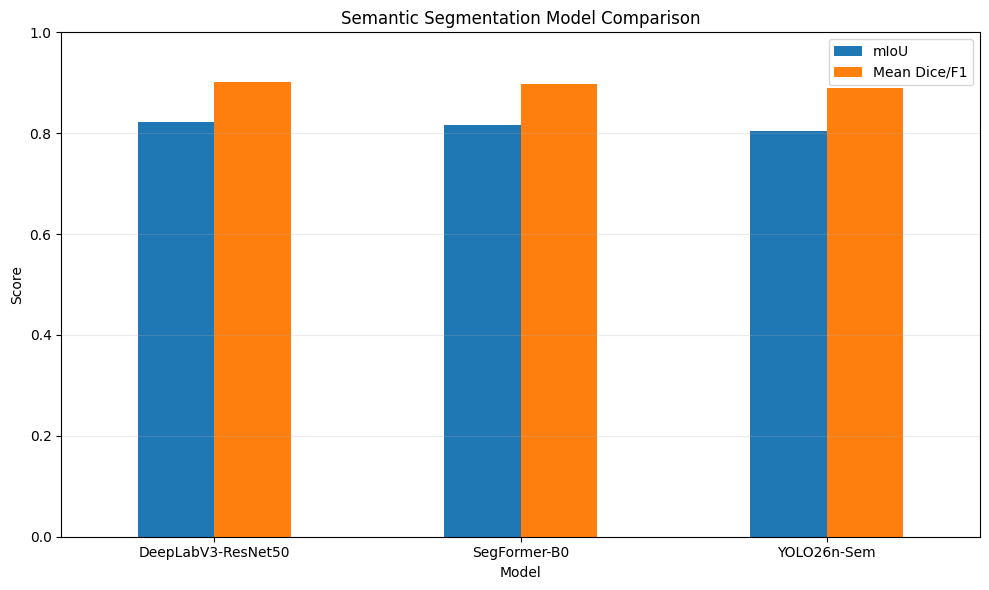

In [19]:

chart_df = (
    comparison_df
    .set_index("Model")[
        [
            "mIoU",
            "Mean Dice/F1",
        ]
    ]
)


axis = chart_df.plot(
    kind="bar",
    figsize=(10, 6),
    rot=0,
)


axis.set_title(
    "Semantic Segmentation Model Comparison"
)

axis.set_xlabel("Model")
axis.set_ylabel("Score")
axis.set_ylim(0, 1)

axis.grid(
    axis="y",
    alpha=0.25,
)


plt.tight_layout()

plt.savefig(
    OUTPUT_ROOT
    / "final_model_comparison_chart.png",
    dpi=160,
)

plt.show()

Common test images: 360
Failure threshold: mIoU < 0.5
Images where all three models failed: 29


,image_id,deeplabv3_miou,segformer_miou,yolo26_miou,deeplab_failed,segformer_failed,yolo_failed,failure_count,average_miou,model_disagreement,comparison
0,testing_00247,0.034590,0.033276,0.554169,True,True,False,2,0.207345,0.520893,DeepLabV3 + SegFormer-B0
1,testing_00005,0.209603,0.206905,0.248029,True,True,True,3,0.221512,0.041124,All three models failed
2,testing_00172,0.264381,0.264381,0.264381,True,True,True,3,0.264381,0.000000,All three models failed
3,testing_00088,0.457611,0.207199,0.207199,True,True,True,3,0.290670,0.250412,All three models failed
4,testing_00341,0.346594,0.369858,0.193062,True,True,True,3,0.303171,0.176796,All three models failed
5,testing_00038,0.588366,0.120329,0.304908,False,True,True,2,0.337868,0.468038,SegFormer-B0 + YOLO26-Sem
6,testing_00135,0.342026,0.380569,0.375961,True,True,True,3,0.366186,0.038544,All three models failed
7,testing_00124,0.301773,0.513129,0.297752,True,False,True,2,0.370885,0.215377,DeepLabV3 + YOLO26-Sem
8,testing_00359,0.385172,0.396468,0.337898,True,True,True,3,0.373179,0.058570,All three models failed
9,testing_00045,0.440617,0.383398,0.347103,True,True,True,3,0.390373,0.093515,All three models failed


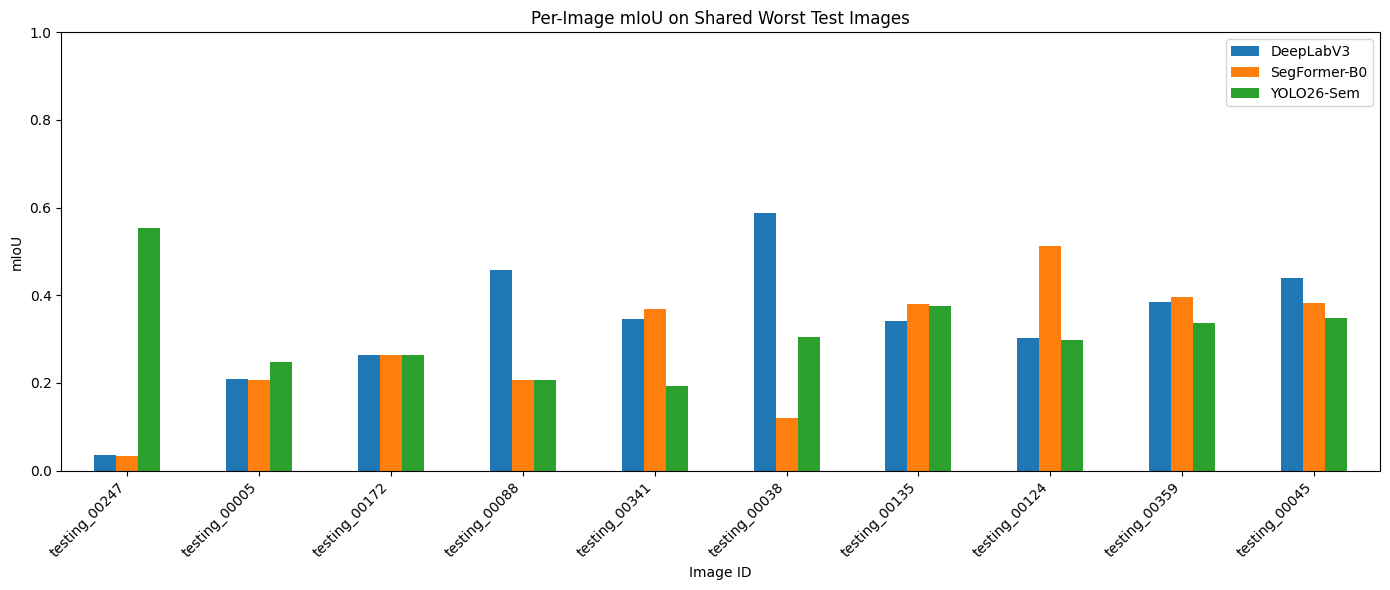

In [20]:

FAILURE_THRESHOLD = 0.50


def locate_per_image_file(
    output_root: Path,
    exact_name: str,
    model_keyword: str,
) -> Path:

    exact_path = (
        output_root
        / exact_name
    )

    if exact_path.exists():
        return exact_path

    candidates = sorted(
        [
            path
            for path in output_root.rglob("*.csv")
            if (
                "per_image" in path.name.lower()
                and "metric" in path.name.lower()
                and model_keyword.lower()
                in path.name.lower()
            )
        ]
    )

    assert candidates, (
        f"Per-image metric CSV was not found "
        f"inside {output_root}."
    )

    return candidates[0]


NB1_PER_IMAGE_FILE = locate_per_image_file(
    NB1_OUTPUT_ROOT,
    "deeplabv3_per_image_test_metrics.csv",
    "deeplab",
)

NB2_PER_IMAGE_FILE = locate_per_image_file(
    NB2_OUTPUT_ROOT,
    "segformer_per_image_test_metrics.csv",
    "segformer",
)

NB3_PER_IMAGE_FILE = (
    OUTPUT_ROOT
    / "yolo_sem_per_image_test_metrics.csv"
)

assert NB3_PER_IMAGE_FILE.exists(), (
    "NB3 per-image test metrics were not saved."
)


deeplab_per_image_df = pd.read_csv(
    NB1_PER_IMAGE_FILE
)

segformer_per_image_df = pd.read_csv(
    NB2_PER_IMAGE_FILE
)

yolo_per_image_df = pd.read_csv(
    NB3_PER_IMAGE_FILE
)


def prepare_failure_table(
    dataframe: pd.DataFrame,
    output_column: str,
) -> pd.DataFrame:

    assert "image_id" in dataframe.columns, (
        "image_id column was not found."
    )

    metric_candidates = [
        "mean_iou",
        "miou",
        "mIoU",
        "per_image_miou",
    ]

    metric_column = next(
        (
            column
            for column in metric_candidates
            if column in dataframe.columns
        ),
        None,
    )

    assert metric_column is not None, (
        "Per-image mIoU column was not found."
    )

    table = dataframe[
        [
            "image_id",
            metric_column,
        ]
    ].copy()

    table.columns = [
        "image_id",
        output_column,
    ]

    table["image_id"] = (
        table["image_id"]
        .astype(str)
    )

    return table


deeplab_failure_df = prepare_failure_table(
    deeplab_per_image_df,
    "deeplabv3_miou",
)

segformer_failure_df = prepare_failure_table(
    segformer_per_image_df,
    "segformer_miou",
)

yolo_failure_df = prepare_failure_table(
    yolo_per_image_df,
    "yolo26_miou",
)


failure_overlap_df = (
    deeplab_failure_df
    .merge(
        segformer_failure_df,
        on="image_id",
        how="inner",
    )
    .merge(
        yolo_failure_df,
        on="image_id",
        how="inner",
    )
)

assert len(failure_overlap_df) == len(test_df), (
    "The three per-image files do not contain "
    "the same full test set."
)


metric_columns = [
    "deeplabv3_miou",
    "segformer_miou",
    "yolo26_miou",
]


failure_overlap_df[
    "deeplab_failed"
] = (
    failure_overlap_df[
        "deeplabv3_miou"
    ]
    < FAILURE_THRESHOLD
)

failure_overlap_df[
    "segformer_failed"
] = (
    failure_overlap_df[
        "segformer_miou"
    ]
    < FAILURE_THRESHOLD
)

failure_overlap_df[
    "yolo_failed"
] = (
    failure_overlap_df[
        "yolo26_miou"
    ]
    < FAILURE_THRESHOLD
)


failure_columns = [
    "deeplab_failed",
    "segformer_failed",
    "yolo_failed",
]


failure_overlap_df[
    "failure_count"
] = failure_overlap_df[
    failure_columns
].sum(axis=1)


failure_overlap_df[
    "average_miou"
] = failure_overlap_df[
    metric_columns
].mean(axis=1)


failure_overlap_df[
    "model_disagreement"
] = (
    failure_overlap_df[
        metric_columns
    ].max(axis=1)
    -
    failure_overlap_df[
        metric_columns
    ].min(axis=1)
)


def comparison_label(
    row: pd.Series,
) -> str:

    failed_models = []

    if row["deeplab_failed"]:
        failed_models.append(
            "DeepLabV3"
        )

    if row["segformer_failed"]:
        failed_models.append(
            "SegFormer-B0"
        )

    if row["yolo_failed"]:
        failed_models.append(
            "YOLO26-Sem"
        )

    if len(failed_models) == 3:
        return "All three models failed"

    if len(failed_models) == 0:
        return "No model failed"

    return " + ".join(
        failed_models
    )


failure_overlap_df[
    "comparison"
] = failure_overlap_df.apply(
    comparison_label,
    axis=1,
)


all_three_failure_count = int(
    (
        failure_overlap_df[
            "failure_count"
        ]
        == 3
    ).sum()
)


shared_worst_df = (
    failure_overlap_df
    .sort_values(
        [
            "average_miou",
            "model_disagreement",
        ],
        ascending=[
            True,
            False,
        ],
    )
    .head(10)
    .reset_index(drop=True)
)


failure_overlap_df.to_csv(
    OUTPUT_ROOT
    / "failure_overlap_comparison.csv",
    index=False,
)

shared_worst_df.to_csv(
    OUTPUT_ROOT
    / "three_model_shared_worst_images.csv",
    index=False,
)


print(
    "Common test images:",
    len(failure_overlap_df),
)

print(
    "Failure threshold:",
    f"mIoU < {FAILURE_THRESHOLD}",
)

print(
    "Images where all three models failed:",
    all_three_failure_count,
)

display(
    shared_worst_df
)


plot_df = (
    shared_worst_df
    .set_index("image_id")[
        metric_columns
    ]
)

axis = plot_df.plot(
    kind="bar",
    figsize=(14, 6),
)

axis.set_title(
    "Per-Image mIoU on Shared Worst Test Images"
)

axis.set_xlabel(
    "Image ID"
)

axis.set_ylabel(
    "mIoU"
)

axis.set_ylim(
    0,
    1,
)

axis.legend(
    [
        "DeepLabV3",
        "SegFormer-B0",
        "YOLO26-Sem",
    ]
)

plt.xticks(
    rotation=45,
    ha="right",
)

plt.tight_layout()

plt.savefig(
    OUTPUT_ROOT
    / "three_model_shared_failure_comparison.png",
    dpi=160,
    bbox_inches="tight",
)

plt.show()

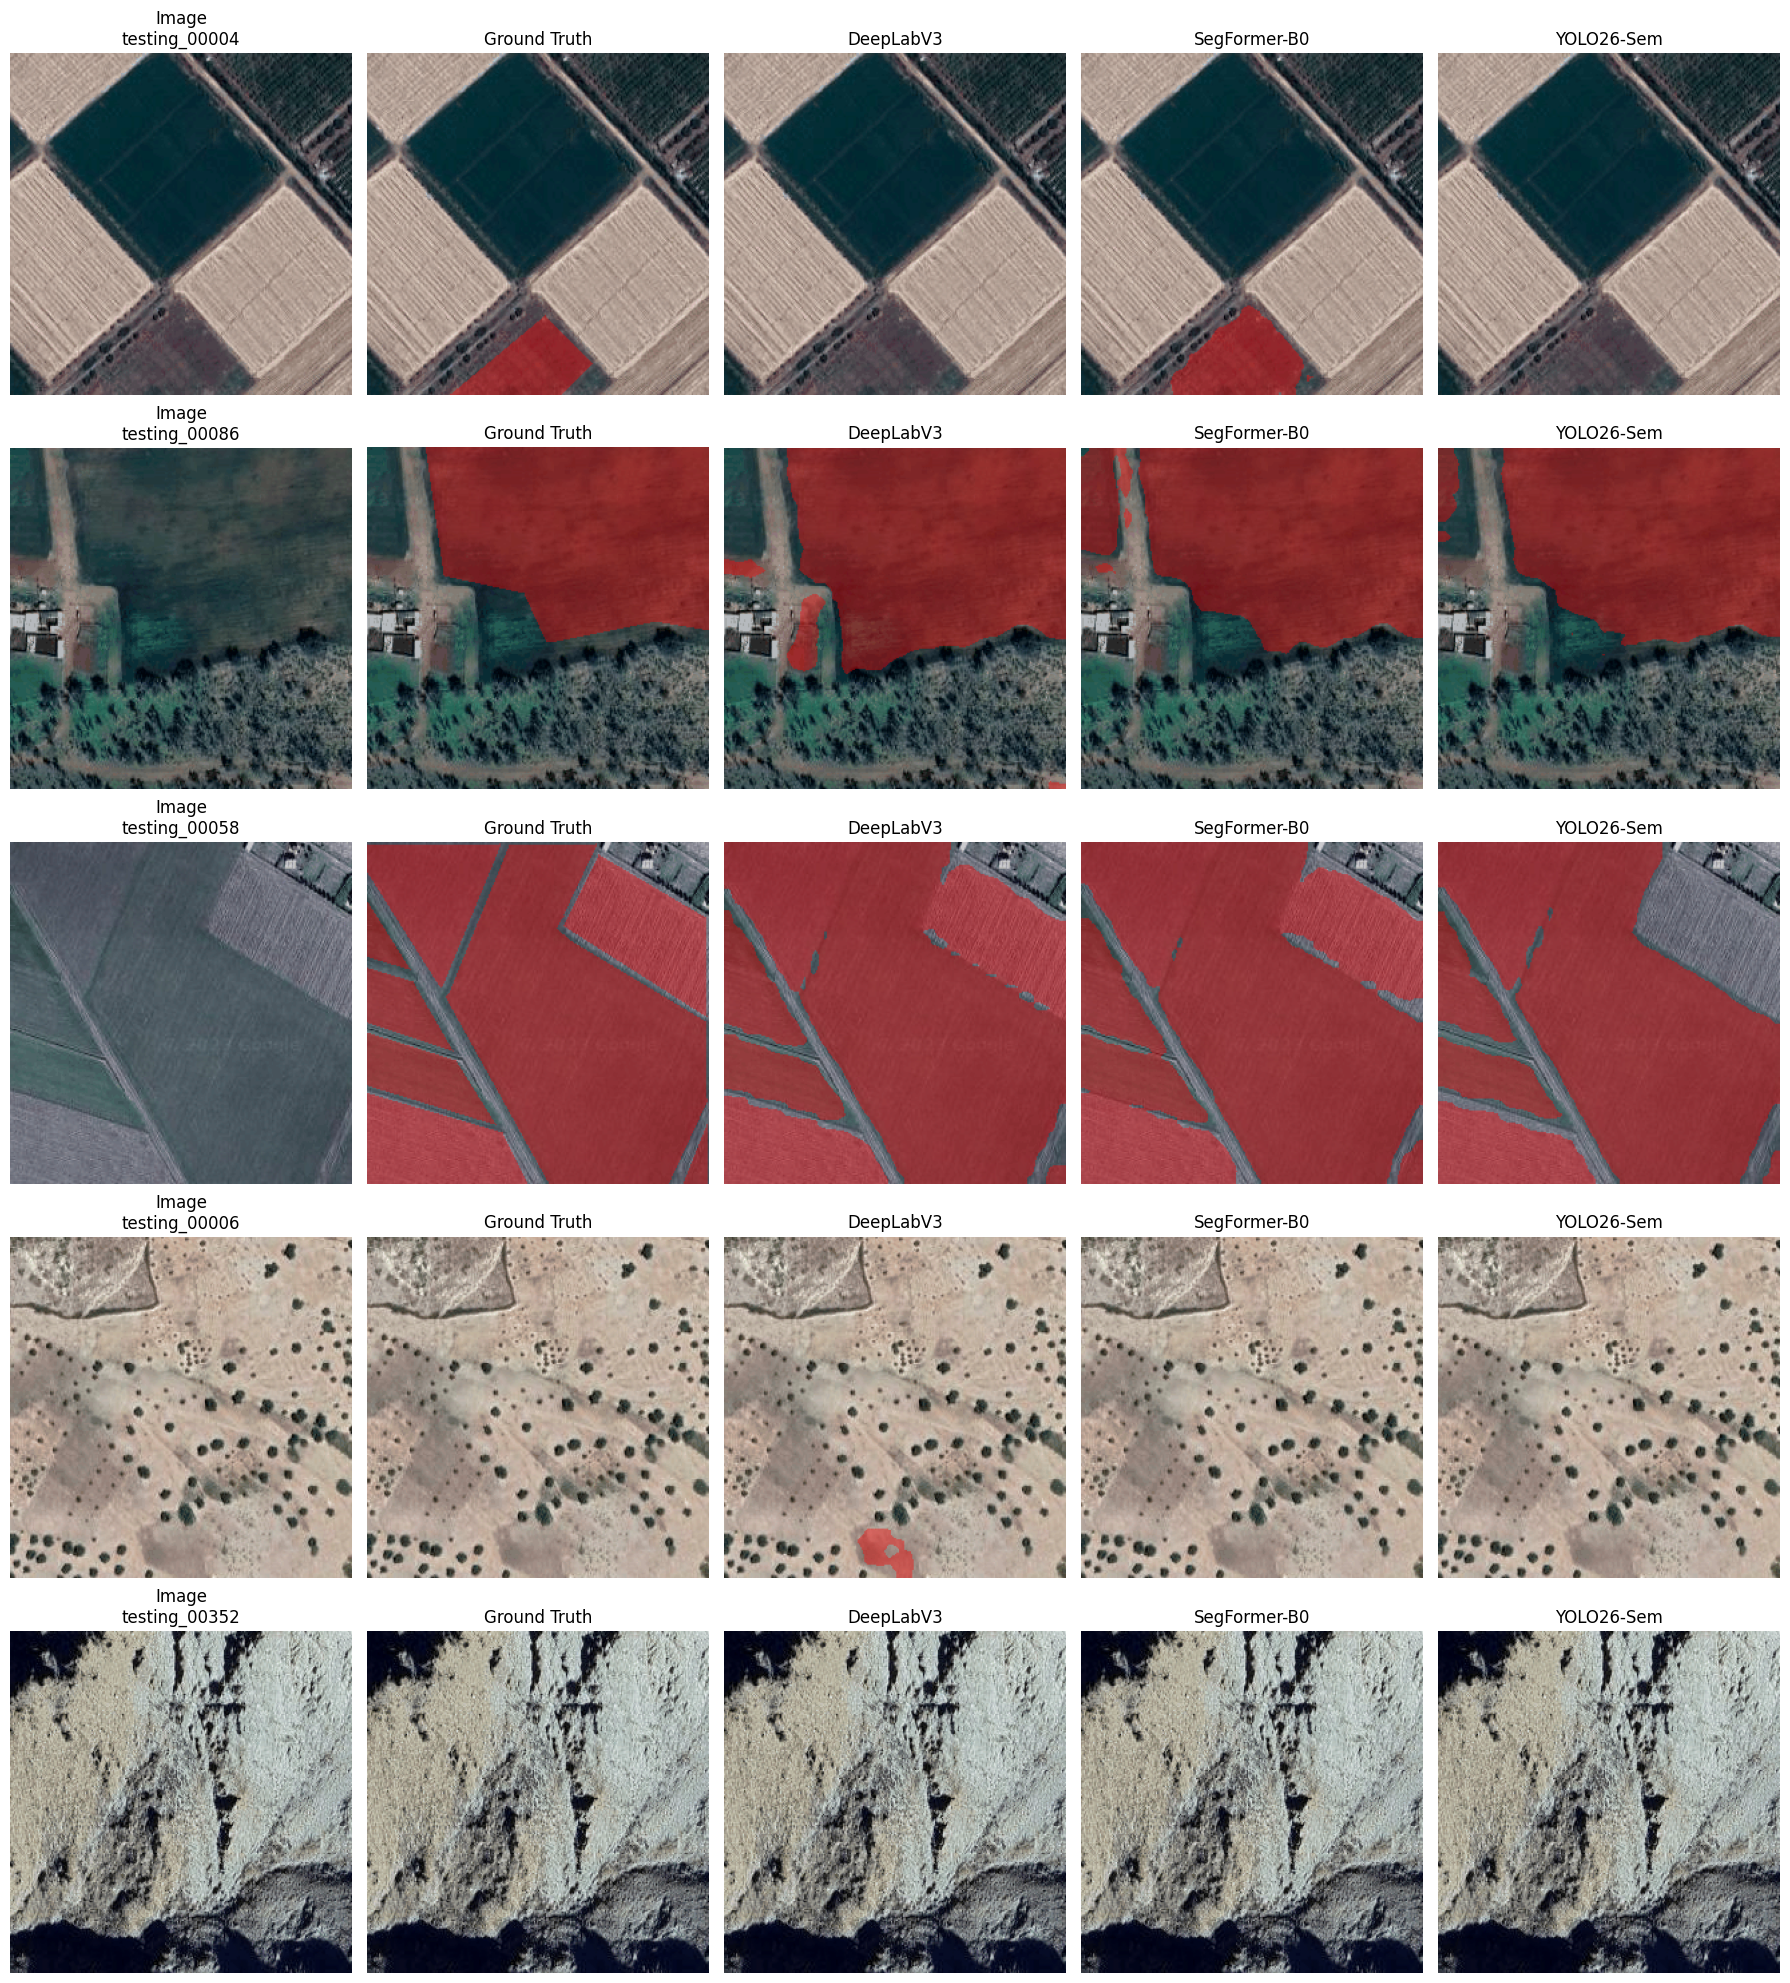

In [21]:


def find_prediction_file(
    output_root: Path,
    image_id: str,
    model_keyword: str,
) -> Path:

    candidates = [
        path
        for path in output_root.rglob("*.png")
        if (
            str(image_id) in path.name
            and model_keyword.lower()
            in path.name.lower()
            and "pred" in path.name.lower()
        )
    ]

    assert candidates, (
        f"Prediction not found for "
        f"{image_id} in {output_root}"
    )

    return sorted(candidates)[0]


fig, axes = plt.subplots(
    len(comparison_ids),
    5,
    figsize=(
        18,
        4 * len(comparison_ids),
    ),
)


if len(comparison_ids) == 1:
    axes = np.expand_dims(
        axes,
        axis=0,
    )


for row_index, image_id in enumerate(
    comparison_ids
):

    manifest_row = (
        test_df[
            test_df[
                "image_id"
            ].astype(str)
            == str(image_id)
        ]
        .iloc[0]
    )


    image = np.asarray(
        Image.open(
            DATA_ROOT
            / manifest_row[
                "image_relpath"
            ]
        ).convert("RGB"),
        dtype=np.uint8,
    )


    image_float = (
        image.astype(np.float32)
        / 255.0
    )


    ground_truth = load_mask(
        NB0_OUTPUT_ROOT
        / manifest_row[
            "encoded_mask_relpath"
        ]
    ).astype(np.uint8)


    deeplab_prediction = np.asarray(
        Image.open(
            find_prediction_file(
                NB1_OUTPUT_ROOT,
                str(image_id),
                "deeplabv3",
            )
        ),
        dtype=np.uint8,
    )


    segformer_prediction = np.asarray(
        Image.open(
            find_prediction_file(
                NB2_OUTPUT_ROOT,
                str(image_id),
                "segformer",
            )
        ),
        dtype=np.uint8,
    )


    yolo_prediction = np.asarray(
        Image.open(
            find_prediction_file(
                OUTPUT_ROOT,
                str(image_id),
                "yolo_sem",
            )
        ),
        dtype=np.uint8,
    )


    axes[row_index, 0].imshow(
        image_float
    )

    axes[row_index, 0].set_title(
        f"Image\n{image_id}"
    )


    axes[row_index, 1].imshow(
        overlay_mask(
            image_float,
            ground_truth,
        )
    )

    axes[row_index, 1].set_title(
        "Ground Truth"
    )


    axes[row_index, 2].imshow(
        overlay_mask(
            image_float,
            deeplab_prediction,
        )
    )

    axes[row_index, 2].set_title(
        "DeepLabV3"
    )


    axes[row_index, 3].imshow(
        overlay_mask(
            image_float,
            segformer_prediction,
        )
    )

    axes[row_index, 3].set_title(
        "SegFormer-B0"
    )


    axes[row_index, 4].imshow(
        overlay_mask(
            image_float,
            yolo_prediction,
        )
    )

    axes[row_index, 4].set_title(
        "YOLO26-Sem"
    )


    for axis in axes[row_index]:
        axis.axis("off")


plt.tight_layout()

plt.savefig(
    OUTPUT_ROOT
    / "final_qualitative_comparison.png",
    dpi=160,
)

plt.show()

## 11. Final verdict

In [22]:


best_row = (
    comparison_df
    .sort_values(
        "mIoU",
        ascending=False,
    )
    .iloc[0]
)

worst_row = (
    comparison_df
    .sort_values(
        "mIoU",
        ascending=True,
    )
    .iloc[0]
)


best_model_name = str(
    best_row["Model"]
)

best_model_miou = float(
    best_row["mIoU"]
)

worst_model_name = str(
    worst_row["Model"]
)

worst_model_miou = float(
    worst_row["mIoU"]
)


class_iou_means = {
    "background": float(
        comparison_df[
            "Background IoU"
        ].mean()
    ),
    "landing_site": float(
        comparison_df[
            "Landing-Site IoU"
        ].mean()
    ),
}

hardest_class = min(
    class_iou_means,
    key=class_iou_means.get,
)


common_test_images = int(
    len(failure_overlap_df)
)

shared_failure_percent = (
    100
    * all_three_failure_count
    / common_test_images
)


improvement_suggestion = (
    f"To improve {worst_model_name}, test a "
    "class-imbalance-aware loss or stronger "
    "boundary-focused augmentation, then tune "
    "the learning rate using validation mIoU."
)


final_verdict = (
    f"{best_model_name} achieved the highest test mIoU "
    f"of {best_model_miou:.4f}. "
    f"The hardest class across the three models was "
    f"{hardest_class}. "
    f"{all_three_failure_count} out of "
    f"{common_test_images} common test images "
    f"({shared_failure_percent:.1f}%) had mIoU below "
    f"{FAILURE_THRESHOLD:.2f} for all three models. "
    f"This indicates that some failures are caused by "
    f"intrinsically difficult images, such as small "
    f"landing-site regions, uncertain boundaries, "
    f"or visually similar terrain. "
    f"{improvement_suggestion}"
)


comparison_payload = {
    "models": comparison_df.to_dict(
        orient="records"
    ),

    "best_model": best_model_name,

    "best_model_miou": best_model_miou,

    "worst_model": worst_model_name,

    "worst_model_miou": worst_model_miou,

    "hardest_class": hardest_class,

    "mean_class_iou_across_models": (
        class_iou_means
    ),

    "failure_analysis": {
        "common_test_images": (
            common_test_images
        ),

        "failure_threshold": (
            FAILURE_THRESHOLD
        ),

        "all_three_failure_count": (
            all_three_failure_count
        ),

        "all_three_failure_percentage": (
            shared_failure_percent
        ),
    },

    "improvement_suggestion": (
        improvement_suggestion
    ),

    "final_verdict": final_verdict,

    "saved_at": datetime.now(
        timezone.utc
    ).isoformat(),
}


with (
    OUTPUT_ROOT
    / "three_model_comparison.json"
).open(
    "w",
    encoding="utf-8",
) as file:

    json.dump(
        comparison_payload,
        file,
        indent=2,
    )


summary_text = f"""
## NB3 — Final Summary

### YOLO26-Sem test result

- Test mIoU: {test_metrics['mean_iou']:.4f}
- Background IoU: {test_metrics['per_class_iou']['background']:.4f}
- Landing-site IoU: {test_metrics['per_class_iou']['landing_site']:.4f}
- Overall pixel accuracy: {test_metrics['overall_pixel_accuracy']:.4f}
- Mean pixel accuracy: {test_metrics['mean_pixel_accuracy']:.4f}
- Mean Dice/F1: {test_metrics['mean_dice']:.4f}
- Completed epochs: {actual_trained_epochs}
- Training time: {training_time_minutes:.2f} minutes

### Task H final verdict

{final_verdict}
""".strip()


with (
    OUTPUT_ROOT
    / "nb3_final_summary.md"
).open(
    "w",
    encoding="utf-8",
) as file:

    file.write(
        summary_text
        + "\n"
    )


# Shared results file required by the assignment structure.
shared_results = {
    "NB1": deeplab_payload,
    "NB2": segformer_payload,
    "NB3": yolo_payload,
    "Task_H": comparison_payload,
}


with (
    OUTPUT_ROOT
    / "results.json"
).open(
    "w",
    encoding="utf-8",
) as file:

    json.dump(
        shared_results,
        file,
        indent=2,
    )


display(
    Markdown(
        summary_text
    )
)

## NB3 — Final Summary

### YOLO26-Sem test result

- Test mIoU: 0.8041
- Background IoU: 0.8754
- Landing-site IoU: 0.7329
- Overall pixel accuracy: 0.9071
- Mean pixel accuracy: 0.8816
- Mean Dice/F1: 0.8897
- Completed epochs: 50
- Training time: 14.84 minutes

### Task H final verdict

DeepLabV3-ResNet50 achieved the highest test mIoU of 0.8220. The hardest class across the three models was landing_site. 29 out of 360 common test images (8.1%) had mIoU below 0.50 for all three models. This indicates that some failures are caused by intrinsically difficult images, such as small landing-site regions, uncertain boundaries, or visually similar terrain. To improve YOLO26n-Sem, test a class-imbalance-aware loss or stronger boundary-focused augmentation, then tune the learning rate using validation mIoU.

### Interpretation

The final comparison uses the identical NB0 test split for all three models. Model selection is based on test mIoU only for final reporting; validation mIoU was used during training to select each model's best checkpoint. A per-image mIoU below 0.50 is used only as a transparent error-analysis threshold.

### References

- Ultralytics, *YOLO26 Semantic Segmentation*.
- Hugging Face, *SegFormer Model Documentation*.
- PyTorch, *DeepLabV3 Documentation*.

## 12. Final NB3 output check

In [23]:


required_outputs = [
    OUTPUT_ROOT
    / "yolo_sem_metrics.json",

    OUTPUT_ROOT
    / "yolo_sem_per_class_metrics.csv",

    OUTPUT_ROOT
    / "yolo_sem_per_image_test_metrics.csv",

    OUTPUT_ROOT
    / "yolo_sem_confusion_matrix.csv",

    OUTPUT_ROOT
    / "yolo_sem_confusion_matrix.png",

    OUTPUT_ROOT
    / "yolo_sem_training_history.csv",

    OUTPUT_ROOT
    / "yolo_sem_training_curves.png",

    OUTPUT_ROOT
    / "yolo_sem_worst_examples.png",

    OUTPUT_ROOT
    / "yolo_sem_error_analysis.md",

    OUTPUT_ROOT
    / "yolo_sem_comparison_predictions.csv",

    OUTPUT_ROOT
    / "final_three_model_comparison.csv",

    OUTPUT_ROOT
    / "final_model_comparison_chart.png",

    OUTPUT_ROOT
    / "failure_overlap_comparison.csv",

    OUTPUT_ROOT
    / "three_model_shared_worst_images.csv",

    OUTPUT_ROOT
    / "three_model_shared_failure_comparison.png",

    OUTPUT_ROOT
    / "final_qualitative_comparison.png",

    OUTPUT_ROOT
    / "three_model_comparison.json",

    OUTPUT_ROOT
    / "nb3_final_summary.md",

    OUTPUT_ROOT
    / "results.json",
]


missing_outputs = [
    output_path
    for output_path in required_outputs
    if not output_path.exists()
]


assert not missing_outputs, (
    "Missing required outputs:\n"
    + "\n".join(
        str(path)
        for path in missing_outputs
    )
)


assert actual_trained_epochs >= 50, (
    "NB3 must complete at least 50 epochs."
)


assert len(test_per_image_df) == len(test_df), (
    "The full test split was not evaluated."
)


assert len(failure_overlap_df) == len(test_df), (
    "Task H did not compare all common test images."
)


print(
    "NB3 completed successfully."
)

print(
    "All required Task E, F, G, and H outputs exist."
)

print(
    "Completed epochs:",
    actual_trained_epochs,
)

print(
    "Evaluated test images:",
    len(test_per_image_df),
)

print(
    "Compared common test images:",
    len(failure_overlap_df),
)

NB3 completed successfully.
All required Task E, F, G, and H outputs exist.
Completed epochs: 50
Evaluated test images: 360
Compared common test images: 360
